<div dir="rtl">

# بهبود کنتراست تصویر با منطق فازی
### مثال کتاب پردازش تصویر گونزالس و وودز — تصویر انیشتین

در این نوت‌بوک مثال بخش «استفاده از مجموعه‌های فازی برای تبدیل شدت روشنایی» از کتاب گونزالس را قدم‌به‌قدم پیاده می‌کنیم و نتیجه را با یکسان‌سازی هیستوگرام مقایسه می‌کنیم.

ایده‌ی اصلی، سه قانون زبانی ساده است:

- **R1:** اگر پیکسل **تیره** است، آن را **تیره‌تر** کن.
- **R2:** اگر پیکسل **خاکستری** است، آن را **خاکستری** نگه دار.
- **R3:** اگر پیکسل **روشن** است، آن را **روشن‌تر** کن.

</div>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams['figure.dpi'] = 110

<div dir="rtl">

## ۱. خواندن تصویر و بررسی هیستوگرام

تصویر `Fig0354(a)(einstein_orig).tif` از سایت رسمی کتاب گرفته شده است. همان‌طور که در هیستوگرام می‌بینید، شدت روشنایی پیکسل‌ها فقط بخش کوچکی از بازه‌ی ۰ تا ۲۵۵ را پوشش می‌دهد؛ به همین دلیل تصویر کم‌کنتراست و «کدر» به نظر می‌رسد.

</div>

ابعاد: (600, 490) | کمینه: 74 | بیشینه: 178 | میانگین: 102.4


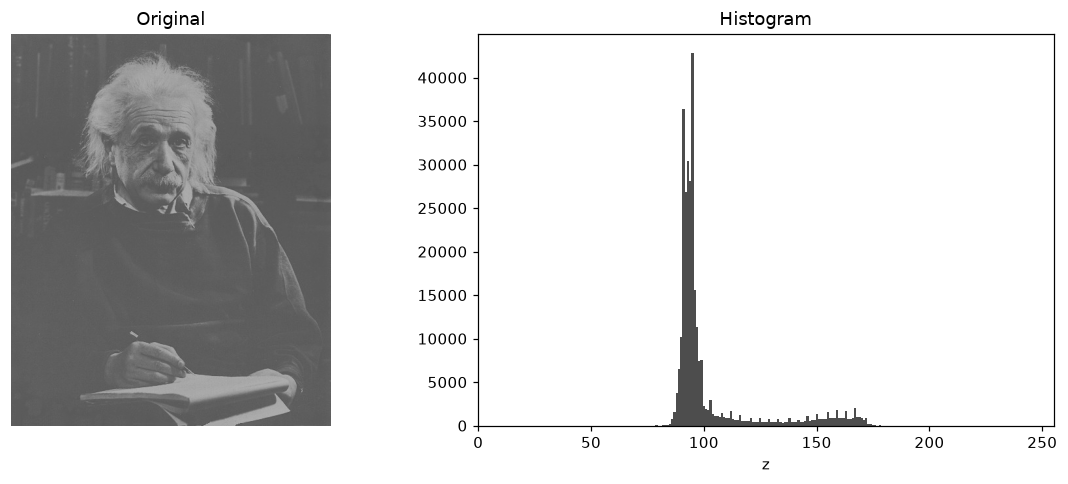

In [3]:
img = np.array(Image.open('downloads/einstein.tif').convert('L'))
print('ابعاد:', img.shape, '| کمینه:', img.min(), '| بیشینه:', img.max(), '| میانگین: %.1f' % img.mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].bar(np.arange(256), np.bincount(img.ravel(), minlength=256), width=1, color='0.3')
ax[1].set_xlim(0, 255); ax[1].set_title('Histogram'); ax[1].set_xlabel('z');
plt.tight_layout(); plt.show()

<div dir="rtl">

## ۲. فازی‌سازی ورودی: توابع عضویت

برای هر شدت روشنایی $z$ سه درجه‌ی عضویت تعریف می‌کنیم:

- $\mu_{dark}(z)$: شیب نزولی — در تیره‌ترین مقدار برابر ۱ و در قله‌ی «خاکستری» برابر ۰
- $\mu_{gray}(z)$: مثلثی — قله‌اش روی مقدار $g$
- $\mu_{bright}(z)$: شیب صعودی — از قله‌ی «خاکستری» تا روشن‌ترین مقدار

مثل کتاب، جای این توابع را از روی هیستوگرام خود تصویر انتخاب می‌کنیم:
«تیره» از کمینه‌ی شدت، «روشن» تا بیشینه‌ی شدت، و قله‌ی «خاکستری» روی **میانگین** شدت. اگر قله‌ی خاکستری را وسط بازه بگذاریم، توده‌ی اصلی پیکسل‌ها (حدود ۹۰ تا ۱۰۰) کاملاً سیاه می‌شود.

</div>

In [4]:
def ramp_down(z, a, b):
    # برای z<=a برابر ۱ و تا z=b به‌صورت خطی به ۰ می‌رسد
    return np.clip((b - z) / (b - a), 0.0, 1.0)

def ramp_up(z, a, b):
    # برای z<=a برابر ۰ و تا z=b به‌صورت خطی به ۱ می‌رسد
    return np.clip((z - a) / (b - a), 0.0, 1.0)

def triangle(z, a, m, b):
    return np.minimum(ramp_up(z, a, m), ramp_down(z, m, b))

def memberships(z, d, g, b):
    mu_dark   = ramp_down(z, d, g)
    mu_gray   = triangle(z, d, g, b)
    mu_bright = ramp_up(z, g, b)
    return mu_dark, mu_gray, mu_bright

d, g, b = float(img.min()), float(img.mean()), float(img.max())
print(f'dark_end = {d:.0f},  gray_peak = {g:.1f},  bright_start = {b:.0f}')

dark_end = 74,  gray_peak = 102.4,  bright_start = 178


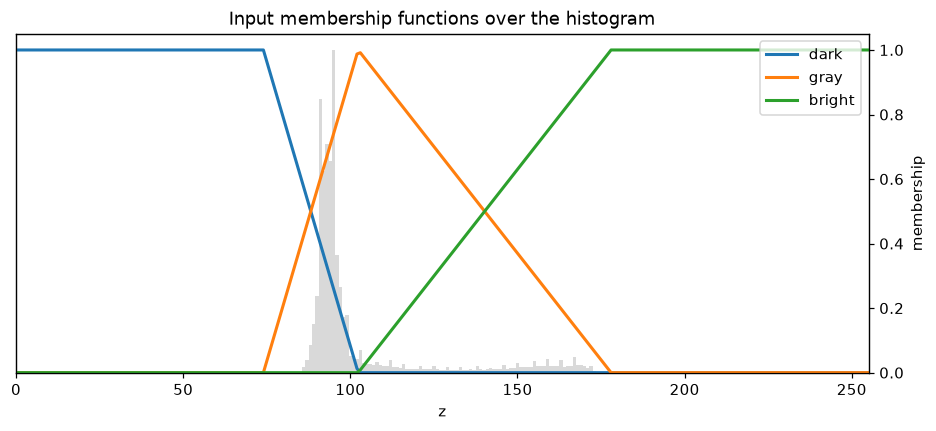

In [5]:
z = np.arange(256, dtype=float)
mu_d, mu_g, mu_b = memberships(z, d, g, b)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(z, np.bincount(img.ravel(), minlength=256), width=1, color='0.85')
ax1.set_yticks([]); ax2 = ax1.twinx()
ax2.plot(z, mu_d, lw=2, label='dark'); ax2.plot(z, mu_g, lw=2, label='gray'); ax2.plot(z, mu_b, lw=2, label='bright')
ax2.set_ylim(0, 1.05); ax2.set_ylabel('membership'); ax1.set_xlabel('z'); ax1.set_xlim(0, 255)
ax2.legend(loc='upper right'); plt.title('Input membership functions over the histogram'); plt.show()

<div dir="rtl">

## ۳. خروجی قوانین و غیرفازی‌سازی

در کتاب، خروجی هر قانون یک مقدار تکین (singleton) است:

| قانون | خروجی |
|---|---|
| تیره‌تر | $v_d = 0$ |
| خاکستری | $v_g = 127$ |
| روشن‌تر | $v_b = 255$ |

وقتی خروجی‌ها تکین باشند، استلزام، تجمیع و غیرفازی‌سازی به روش **مرکز ثقل** به یک فرمول ساده تبدیل می‌شوند:

$$v_0 = \frac{\mu_{dark}(z)\,v_d + \mu_{gray}(z)\,v_g + \mu_{bright}(z)\,v_b}{\mu_{dark}(z) + \mu_{gray}(z) + \mu_{bright}(z)}$$

چون $v_0$ فقط به $z$ بستگی دارد، کافی است آن را یک بار برای ۲۵۶ سطح روشنایی حساب کنیم و در یک جدول (LUT) نگه داریم.

</div>

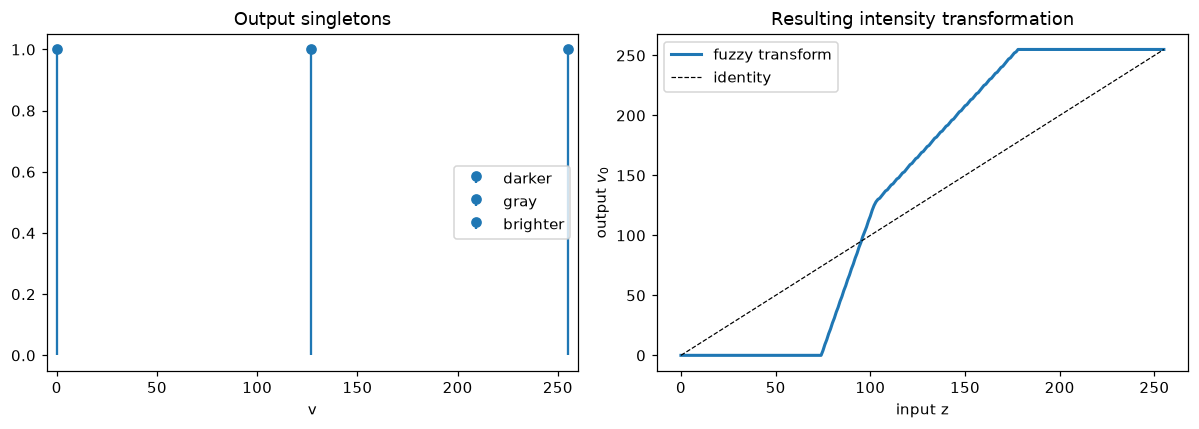

In [6]:
v_d, v_g, v_b = 0.0, 127.0, 255.0

def fuzzy_lut(d, g, b, membership_fn=memberships):
    z = np.arange(256, dtype=float)
    mu_d, mu_g, mu_b = membership_fn(z, d, g, b)
    # 1e-12 added to avoid division by zero
    v0 = (mu_d * v_d + mu_g * v_g + mu_b * v_b) / (mu_d + mu_g + mu_b + 1e-12)
    return np.clip(np.round(v0), 0, 255).astype(np.uint8)

lut = fuzzy_lut(d, g, b)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for v, name in [(v_d, 'darker'), (v_g, 'gray'), (v_b, 'brighter')]:
    ax[0].stem([v], [1], basefmt=' ', label=name)
ax[0].set_xlim(-5, 260); ax[0].set_title('Output singletons'); ax[0].set_xlabel('v'); ax[0].legend()
ax[1].plot(z, lut, lw=2, label='fuzzy transform'); ax[1].plot(z, z, 'k--', lw=0.8, label='identity')
ax[1].set_title('Resulting intensity transformation'); ax[1].set_xlabel('input z'); ax[1].set_ylabel('output $v_0$'); ax[1].legend()
plt.tight_layout(); plt.show()

<div dir="rtl">

> **نکته:** چون توابع عضویت ما خطی‌اند و در هر نقطه مجموعشان ۱ است، تبدیل نهایی در عمل یک کشش کنتراست تکه‌ای-خطی است. توابع گاوسی در بخش ۷ منحنی تبدیل غیرخطی ایجاد می‌کنند.

</div>

<div dir="rtl">

## ۴. اعمال روی تصویر و مقایسه با یکسان‌سازی هیستوگرام

</div>

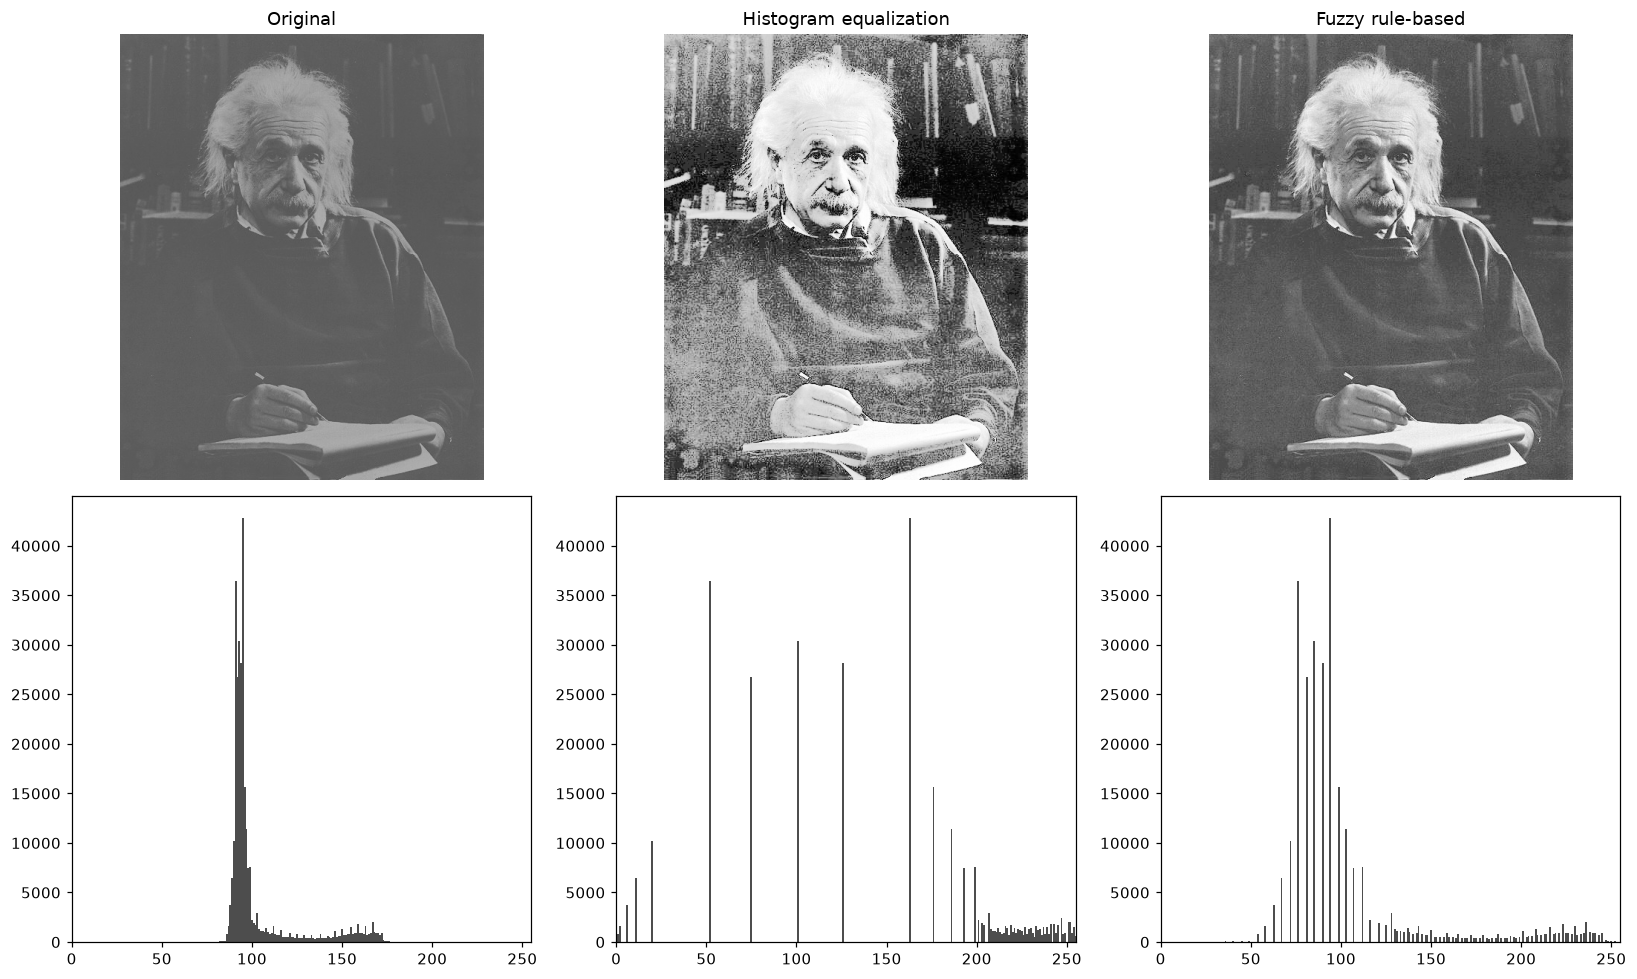

In [7]:
def hist_equalize(img):
    cdf = np.bincount(img.ravel(), minlength=256).cumsum() / img.size
    return np.round(255 * cdf).astype(np.uint8)[img]

fuzzy = lut[img]
he = hist_equalize(img)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for col, (im, title) in enumerate([(img, 'Original'), (he, 'Histogram equalization'), (fuzzy, 'Fuzzy rule-based')]):
    ax[0, col].imshow(im, cmap='gray', vmin=0, vmax=255); ax[0, col].set_title(title); ax[0, col].axis('off')
    ax[1, col].bar(np.arange(256), np.bincount(im.ravel(), minlength=256), width=1, color='0.3')
    ax[1, col].set_xlim(0, 255)
plt.tight_layout(); plt.show()

<div dir="rtl">

همان نتیجه‌ای که کتاب می‌گیرد: یکسان‌سازی هیستوگرام کنتراست را زیاد می‌کند ولی تصویر خشن و پرنویز می‌شود و پس‌زمینه و ژاکت حالت لکه‌لکه پیدا می‌کنند. روش فازی کنتراست را بالا می‌برد و در عین حال ظاهر طبیعی تصویر و جزئیات مو، صورت و ژاکت را حفظ می‌کند.

</div>

<div dir="rtl">

## ۵. اثر جای توابع عضویت

در ادامه‌ی مثال کتاب، با جابه‌جا کردن توابع عضویت نتیجه تغییر می‌کند. چند حالت را کنار هم می‌گذاریم:

</div>

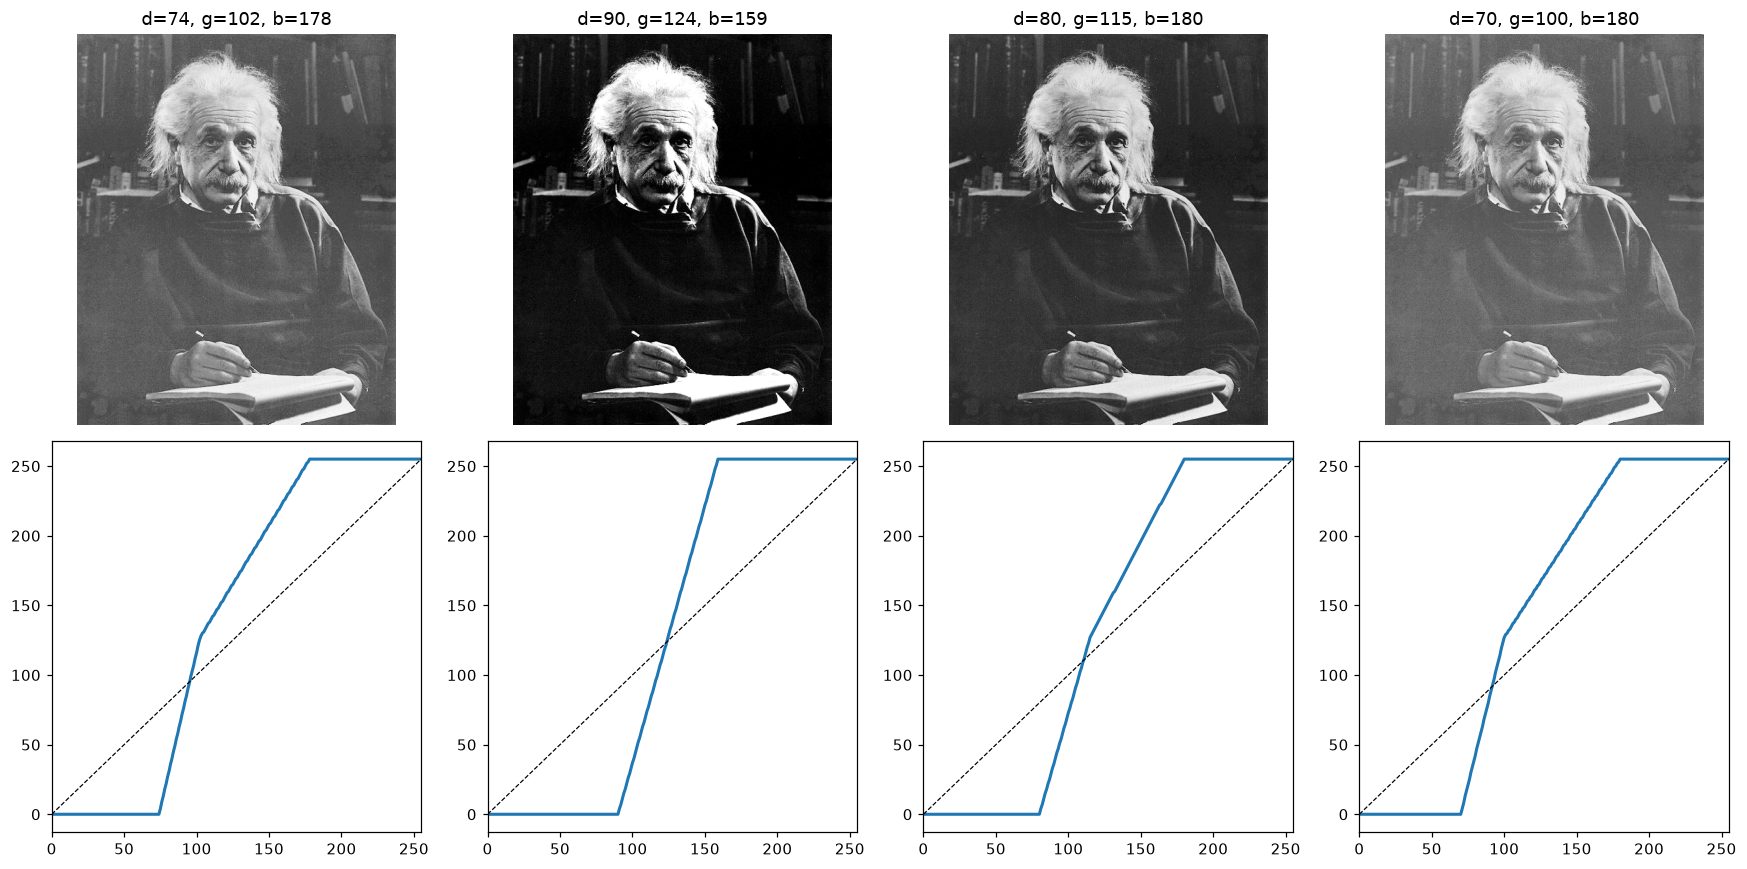

In [8]:
settings = [(d, g, b), (90, 124.5, 159), (80, 115, 180), (70, 100, 180)]
fig, ax = plt.subplots(2, len(settings), figsize=(16, 8))
for i, (dd, gg, bb) in enumerate(settings):
    L = fuzzy_lut(dd, gg, bb)
    ax[0, i].imshow(L[img], cmap='gray', vmin=0, vmax=255); ax[0, i].axis('off')
    ax[0, i].set_title(f'd={dd:.0f}, g={gg:.0f}, b={bb:.0f}')
    ax[1, i].plot(L, lw=2); ax[1, i].plot([0, 255], [0, 255], 'k--', lw=0.8); ax[1, i].set_xlim(0, 255)
plt.tight_layout(); plt.show()

<div dir="rtl">

## ۶. تنظیم تعاملی

با اسلایدرها مرزهای توابع عضویت را تغییر دهید و نتیجه را همان لحظه ببینید (نیاز به `ipywidgets` دارد).

</div>

In [9]:
from ipywidgets import interact, FloatSlider

def show(dark_end=d, gray_peak=g, bright_start=b):
    if not (dark_end < gray_peak < bright_start):
        print('باید dark_end < gray_peak < bright_start باشد'); return
    L = fuzzy_lut(dark_end, gray_peak, bright_start)
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].imshow(L[img], cmap='gray', vmin=0, vmax=255); ax[0].axis('off')
    zz = np.arange(256, dtype=float)
    for m, n in zip(memberships(zz, dark_end, gray_peak, bright_start), ['dark', 'gray', 'bright']):
        ax[1].plot(zz, m * 255, label=n)
    ax[1].plot(L, 'k', lw=2, label='transform'); ax[1].set_xlim(0, 255); ax[1].legend()
    plt.tight_layout(); plt.show()

interact(show,
         dark_end=FloatSlider(value=d, min=0, max=200, step=1),
         gray_peak=FloatSlider(value=g, min=20, max=230, step=1),
         bright_start=FloatSlider(value=b, min=50, max=255, step=1));

interactive(children=(FloatSlider(value=74.0, description='dark_end', max=200.0, step=1.0), FloatSlider(value=…

<div dir="rtl">

## ۷. مقایسهٔ توابع عضویت خطی و گاوسی

توابع عضویت خطی (شیب و مثلث) روش اصلی‌اند. برای مقایسه، توابع گاوسی را با همان پارامترهای $(d, g, b)$ می‌سازیم.

| خانواده | تیره | خاکستری | روشن | ویژگی |
|---|---|---|---|---|
| **خطی** (کتاب) | شیب نزولی | مثلثی | شیب صعودی | مجموع عضویت‌ها ۱ است؛ تبدیل تکه‌ای-خطی |
| **گاوسی** | نیم‌گاوسی | گاوسی | نیم‌گاوسی | توابع آزادانه هم‌پوشانی دارند و مجموعشان ۱ نیست؛ گذار وسط تندتر است و دنباله‌ی «خاکستری» تا دو سر بازه می‌رسد |

</div>

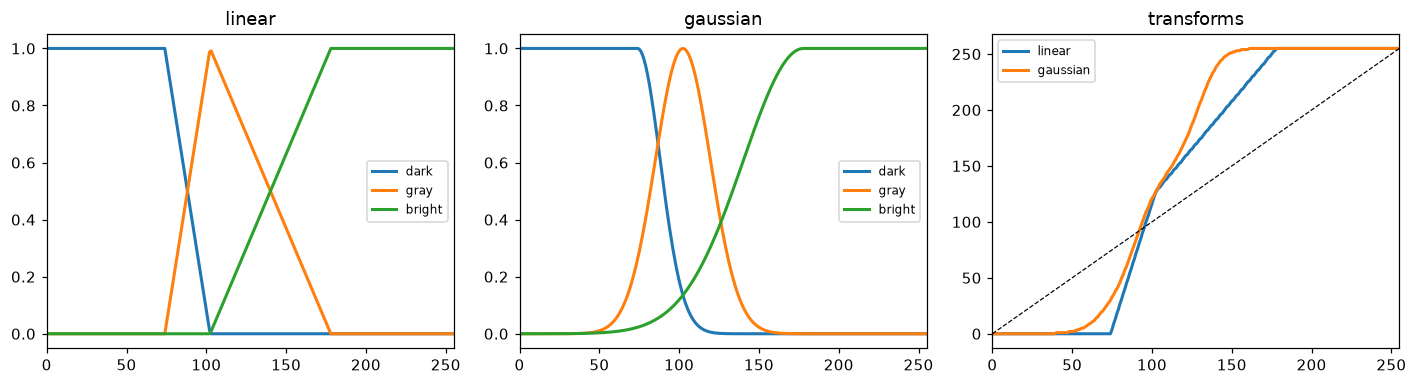

In [10]:
def gaussian(z, center, sigma):
    distance = z - center
    return np.exp(-distance**2 / (2 * sigma**2))


def mf_gauss(z, d, g, b):
    sigma_dark = (g - d) / 2
    sigma_gray = (b - d) / 6
    sigma_bright = (b - g) / 2

    # عضویت تیره تا d و عضویت روشن از b به بعد برابر ۱ است.
    dark = np.where(z <= d, 1.0, gaussian(z, d, sigma_dark))
    gray = gaussian(z, g, sigma_gray)
    bright = np.where(z >= b, 1.0, gaussian(z, b, sigma_bright))
    return dark, gray, bright

FAMILIES = {'linear': memberships, 'gaussian': mf_gauss}

# شکل توابع و منحنی تبدیل هر خانواده روی پارامترهای تصویر انیشتین
z = np.arange(256, dtype=float)
fig, axes = plt.subplots(1, len(FAMILIES) + 1, figsize=(13, 3.6))
ax_transform = axes[-1]
for ax, (name, mf) in zip(axes[:-1], FAMILIES.items()):
    for m, lab in zip(mf(z, d, g, b), ['dark', 'gray', 'bright']):
        ax.plot(z, m, lw=2, label=lab)
    ax.set_title(name)
    ax.set_xlim(0, 255)
    ax.legend(fontsize=8)
    ax_transform.plot(z, fuzzy_lut(d, g, b, mf), lw=2, label=name)
ax_transform.plot(z, z, 'k--', lw=0.8)
ax_transform.set_title('transforms')
ax_transform.set_xlim(0, 255)
ax_transform.legend(fontsize=8)
plt.tight_layout(); plt.show()

<div dir="rtl">

## ۸. آزمایش روی تصاویر دیگر

شش تصویر با مشکل‌های متفاوت انتخاب کرده‌ایم. پنج تصویر از فایل‌های فصل ۳ همان کتاب‌اند و یکی از تصاویر نمونه‌ی کتابخانه‌ی `scikit-image`:

| تصویر | مشکل |
|---|---|
| گرده‌ی گیاه (Fig 3.10) | بازه‌ی خیلی باریک (۹۱ تا ۱۳۸) |
| گرده‌ی تیره (Fig 3.16) | تیره و کم‌کنتراست (۱۳ تا ۸۳) |
| گرده‌ی روشن (Fig 3.20) | روشن و رنگ‌پریده (۱۳۲ تا ۲۵۵) |
| عکس هوایی (Fig 3.9) | رنگ‌پریده، ولی چند پیکسل کل بازه را پر کرده‌اند |
| ماه فوبوس (Fig 3.23) | بیشتر پیکسل‌ها خیلی تیره‌اند، با چند نقطه‌ی روشن |
| ماه (`skimage`) | عکس طبیعی کم‌کنتراست |

برای کم کردن اثر پیکسل‌های پرت، $d$ و $b$ را از **صدک‌های ۰٫۵ و ۹۹٫۵** می‌گیریم. $g$ میانگین شدت تصویر است که با فاصلهٔ دست‌کم یک سطح خاکستری از دو مرز نگه می‌داریم.

</div>

In [11]:
from skimage import data as skdata
# آستانه‌گذاری مبتنی بر صدک
def robust_params(image):
    dark, bright = np.percentile(image, [0.5, 99.5])
    gray = np.clip(image.mean(), dark + 1, bright - 1)
    return dark, gray, bright

def load(p):
    return np.array(Image.open(p).convert('L'))

D = 'downloads/images/'
TESTS = {
    'pollen (narrow)':  load(D + 'Fig0310(b)(washed_out_pollen_image).tif'),
    'pollen (dark)':    load(D + 'Fig0316(4)(bottom_left).tif'),
    'pollen (light)':   load(D + 'Fig0320(1)(top_left).tif'),
    'aerial (washed)':  load(D + 'Fig0309(a)(washed_out_aerial_image).tif'),
    'phobos (dark)':    load(D + 'Fig0323(a)(mars_moon_phobos).tif'),
    'moon (skimage)':   skdata.moon(),
}
for k, im in TESTS.items():
    print(f'{k:18s} shape={im.shape}  range=[{im.min():3d},{im.max():3d}]  (d,g,b)=({", ".join(f"{x:.0f}" for x in robust_params(im))})')

pollen (narrow)    shape=(889, 889)  range=[ 91,138]  (d,g,b)=(91, 109, 134)
pollen (dark)      shape=(500, 500)  range=[ 13, 83]  (d,g,b)=(13, 39, 76)
pollen (light)     shape=(500, 500)  range=[132,255]  (d,g,b)=(132, 196, 255)
aerial (washed)    shape=(769, 765)  range=[  0,255]  (d,g,b)=(48, 197, 254)
phobos (dark)      shape=(1000, 683)  range=[  0,255]  (d,g,b)=(0, 32, 255)
moon (skimage)     shape=(512, 512)  range=[  0,255]  (d,g,b)=(29, 112, 158)


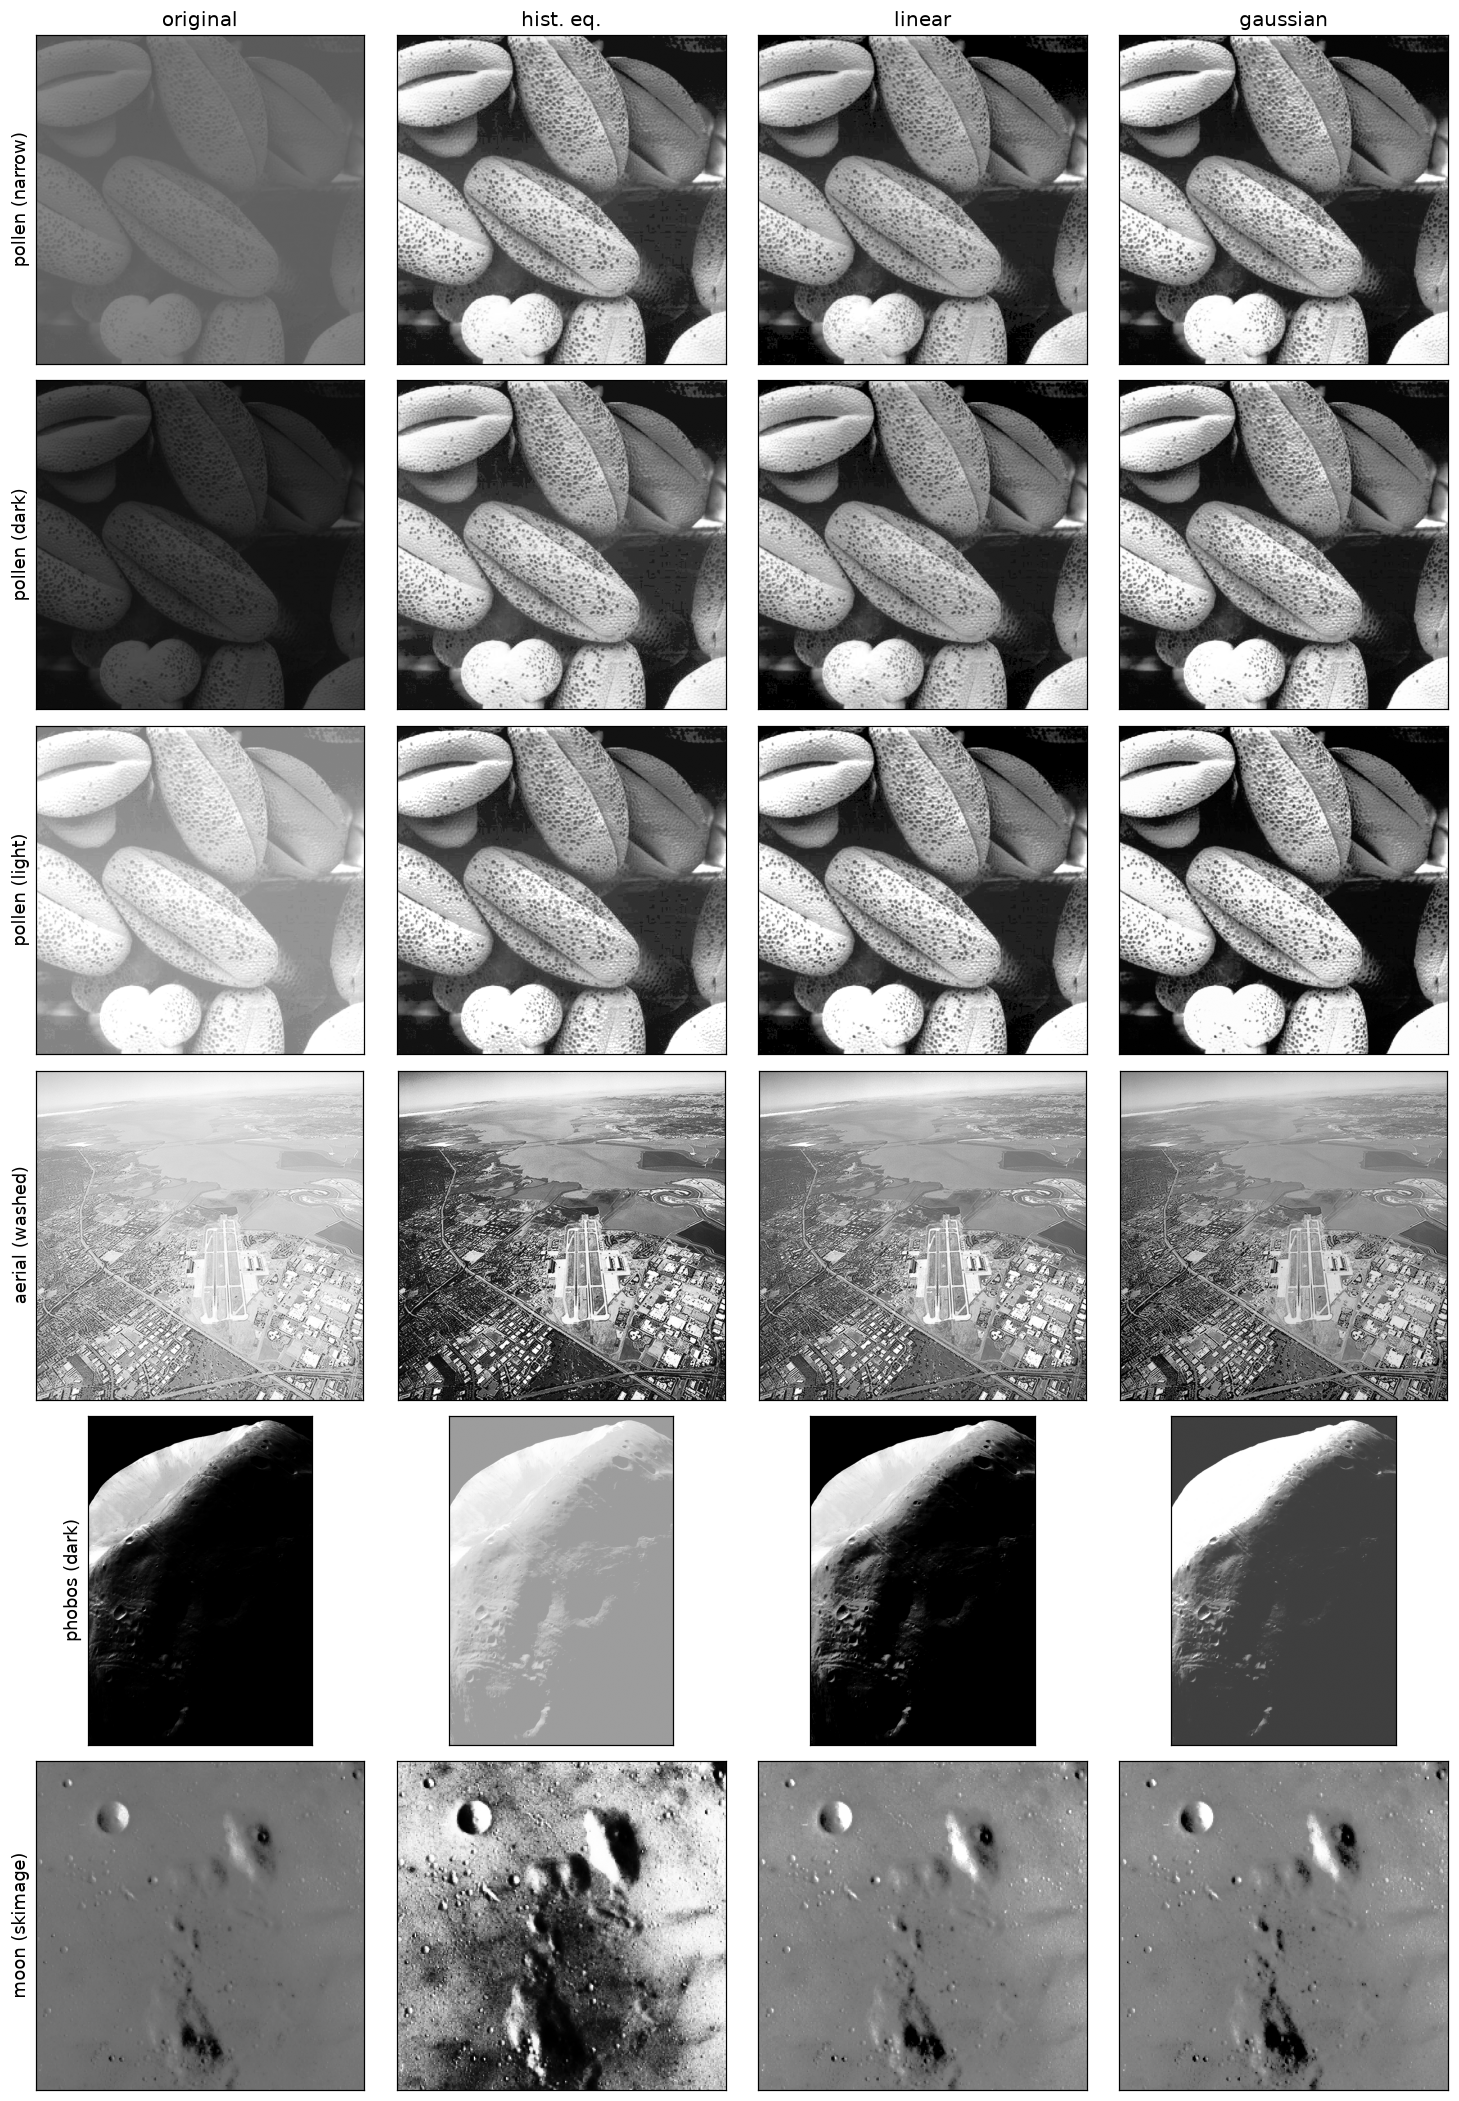

In [12]:
cols = ['original', 'hist. eq.'] + list(FAMILIES)
results = {}
fig, ax = plt.subplots(len(TESTS), len(cols), figsize=(13.6, 3.2 * len(TESTS)))
for r, (name, im) in enumerate(TESTS.items()):
    p = robust_params(im)
    outs = {'original': im, 'hist. eq.': hist_equalize(im)}
    outs.update({fam: fuzzy_lut(*p, membership_fn=mf)[im] for fam, mf in FAMILIES.items()})
    results[name] = outs
    for c, col in enumerate(cols):
        ax[r, c].imshow(outs[col], cmap='gray', vmin=0, vmax=255); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if r == 0: ax[r, c].set_title(col, fontsize=13)
    ax[r, 0].set_ylabel(name, fontsize=12)
plt.tight_layout(); plt.show()

<div dir="rtl">

### منحنی‌های تبدیل روی هیستوگرام هر تصویر

خاکستری کم‌رنگ هیستوگرام تصویر اصلی است. منحنی یکسان‌سازی هیستوگرام (خط‌چین) همان تابع توزیع تجمعی است.

</div>

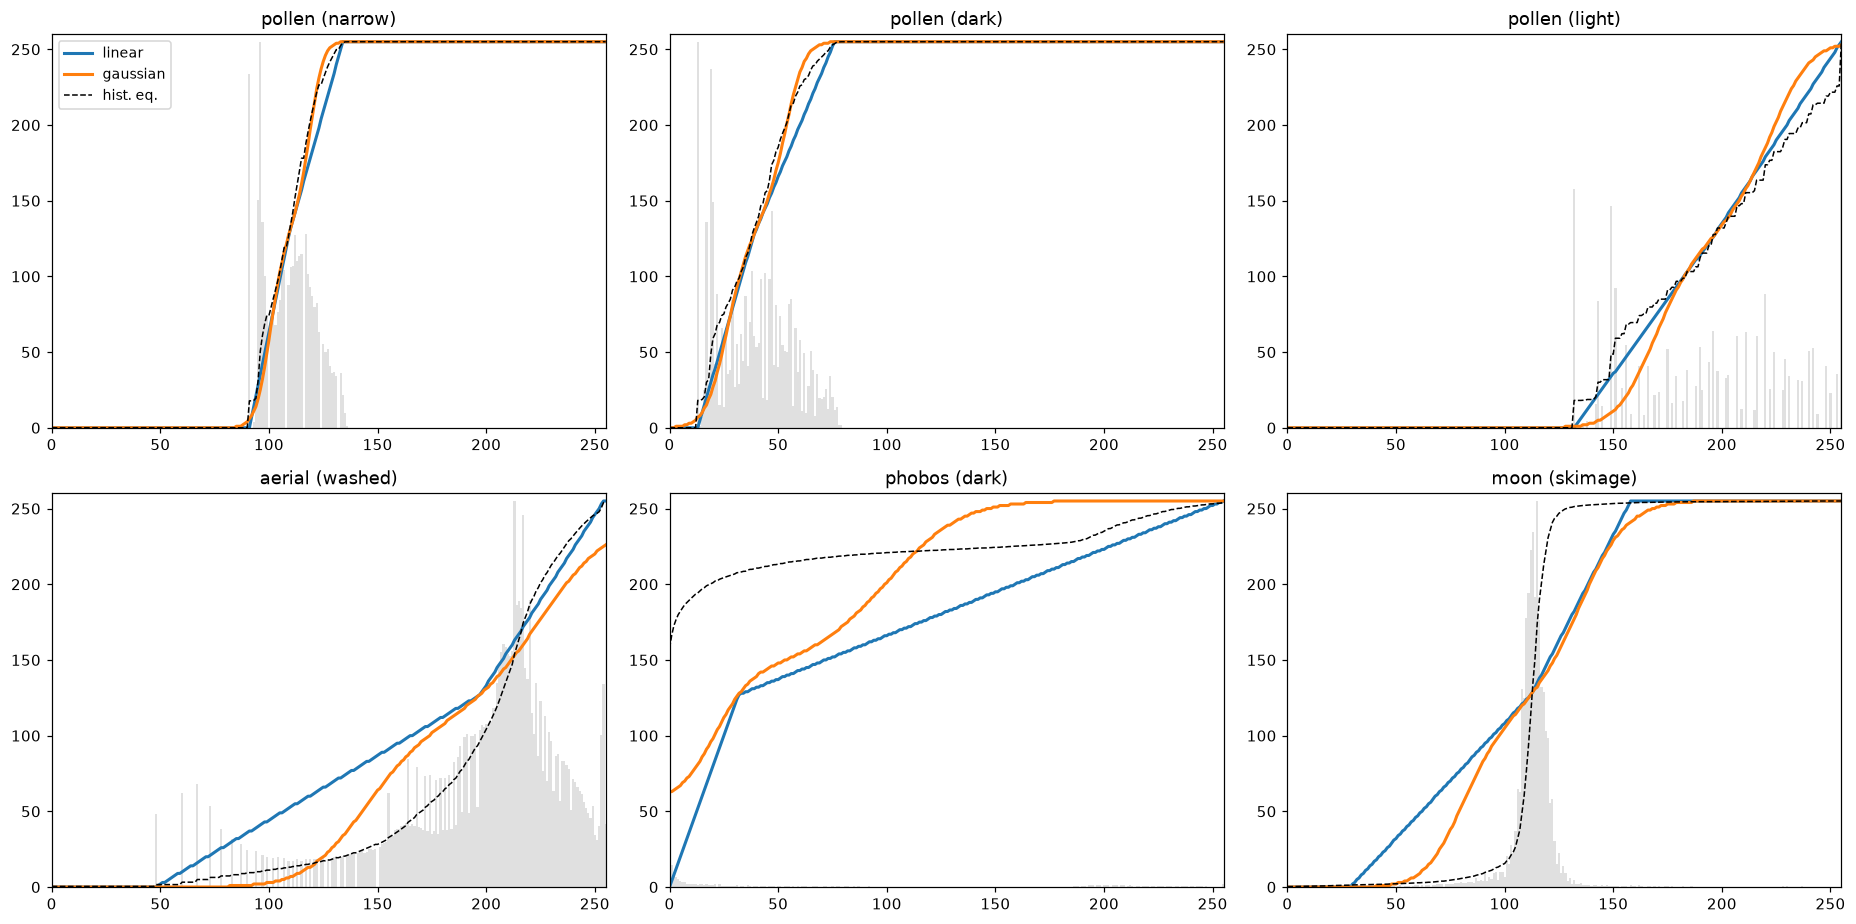

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5)); ax = ax.ravel()
for i, (name, im) in enumerate(TESTS.items()):
    p = robust_params(im)
    h = np.bincount(im.ravel(), minlength=256)
    ax[i].bar(z, h / h.max() * 255, width=1, color='0.88')
    for fam, mf in FAMILIES.items():
        ax[i].plot(fuzzy_lut(*p, membership_fn=mf), lw=2, label=fam)
    ax[i].plot(255 * h.cumsum() / im.size, 'k--', lw=1, label='hist. eq.')
    ax[i].set_xlim(0, 255); ax[i].set_ylim(0, 260); ax[i].set_title(name)
ax[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

<div dir="rtl">

### معیارهای کمّی

- **انحراف معیار**: معیار ساده‌ی کنتراست (بیشتر = کنتراست بیشتر)
- **آنتروپی** (بیت): اطلاعات هیستوگرام. هیچ تبدیل نقطه‌ای آن را **زیاد** نمی‌کند، پس افت کمتر یعنی سطوح خاکستری کمتری با هم ادغام شده‌اند.
- **اشباع ٪**: درصد پیکسل‌هایی که ۰ یا ۲۵۵ هستند. این معیار پیکسل‌هایی را هم که از اول سیاه یا سفید بوده‌اند می‌شمارد؛ مثلاً ۶۲٪ تصویر فوبوس پس‌زمینه‌ی کاملاً سیاه است.

</div>

In [14]:
import pandas as pd

def entropy(im):
    p = np.bincount(im.ravel(), minlength=256) / im.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

rows = []
for name, outs in results.items():
    for method, im in outs.items():
        rows.append({'image': name, 'method': method, 'std': im.std(), 'entropy': entropy(im),
                     'saturated %': 100 * np.mean((im == 0) | (im == 255))})
df = pd.DataFrame(rows)
table = df.pivot(index='image', columns='method').reindex(columns=cols, level=1).loc[list(TESTS)]
table.style.format('{:.1f}').background_gradient(axis=1, subset=pd.IndexSlice[:, ['std']], cmap='Greens')

<div dir="rtl">

### جمع‌بندی (از روی نتایج بالا)

- **یکسان‌سازی هیستوگرام** روی عکس هوایی و ماه بیشترین انحراف معیار را می‌دهد، ولی نتیجه خشن و پرنویز است (ماه را ببینید). روی **فوبوس** کاملاً شکست می‌خورد: چون ۶۲٪ پیکسل‌ها سیاه‌اند، همه‌ی آن‌ها به خاکستری حدود ۱۶۵ نگاشته می‌شوند، پس‌زمینه خاکستری می‌شود و انحراف معیار از ۶۹ به ۳۰ **کم** می‌شود.
- **خطی** (روش کتاب) قابل‌پیش‌بینی‌ترین است و روی هیچ تصویری خراب نمی‌شود. هزینه‌اش این است که هرچه زیر $d$ و بالای $b$ باشد اشباع می‌شود (حدود ۸٪ روی تصاویر گرده).
- **گاوسی** روی گرده‌ها و ماه انحراف معیار بیشتری نسبت به روش خطی دارد، چون گذار وسطش تندتر است. ولی وقتی $g$ به $d$ نزدیک است، دنباله‌ی «خاکستری» در $z=0$ هنوز بزرگ است. در فوبوس ($d=0, g=32$) پس‌زمینه‌ی سیاه به خاکستری حدود ۶۳ می‌رسد و آنتروپی به ۲٫۶ می‌افتد.
- **جای توابع از شکلشان مهم‌تر است.** در عکس هوایی میانگین ۱۹۷ است، پس قله‌ی «خاکستری» روی ۱۹۷ می‌نشیند و هر دو خانواده نیمه‌تاریک‌ها را تیره‌تر می‌کنند. این‌جا تنظیم دستی $g$ (بخش ۶) بیشتر از عوض کردن شکل تابع اثر دارد.

خلاصه: شکل توابع عضویت یک دستگیره‌ی طراحی است. شکل خطی امن‌ترین پیش‌فرض است. گاوسی کنتراست بیشتری می‌دهد ولی وقتی هیستوگرام به یک سر بازه چسبیده باشد مشکل‌ساز می‌شود.

</div>

<div dir="rtl">

## ۹. ذخیره‌ی نتایج

</div>

In [15]:
from pathlib import Path
out = Path('results/notebook'); out.mkdir(parents=True, exist_ok=True)
Image.fromarray(fuzzy).save(out / 'fuzzy.png')
Image.fromarray(he).save(out / 'histeq.png')
print('ذخیره شد در', out)

ذخیره شد در results/notebook
